# 第3节. RAG评估

构建RAG系统后，必须回答一个问题：**这个系统到底好不好？**

RAG评估需要从两个维度同时考量：

* **检索质量** — 搜对了吗？Recall、Precision、MRR
* **生成质量** — 回答对了吗？Faithfulness、Correctness、Relevancy

本节我们就来学习如何系统的对一个RAG系统进行标准化评估。

##### **_理解RAG评估_**：RAG Evaluation = 用标准测试集 + 评价指标，对 RAG 整个系统进行量化测试

## 1. RAG评估工具概览

| 工具 | 特点 | 适用场景 |
|------|------|----------|
| RAGAS | 开源标准，指标最全 | RAG系统日常评估 |
| LangSmith | LangChain官方平台 | 追踪+评估一体化 |
| DeepEval | 语法简洁，CI/CD友好 | 自动化测试流水线 |
| TruLens | 可视化反馈闭环 | 调试和迭代优化 |

其中 **RAGAS** 是社区使用最广的RAG评估框架，提供多个核心指标覆盖检索和生成全流程。

### 1.1 评估数据说明

新版 RAGAS 使用 `ragas.Dataset`（替代旧的 HuggingFace Dataset）。

新版数据集要求以下4个字段：

| 字段名 | 含义 | 来源 | 需要 Ground Truth 的指标 |
|--------|------|------|--------------------------|
| user_input | 用户问题 | 人工或自动生成 | Context Recall / Entities Recall / Noise Sensitivity |
| retrieved_contexts | RAG 系统召回的文档列表 | RAG 检索阶段输出 | 所有检索指标 |
| response | RAG 系统生成的回答 | RAG 生成阶段输出 | Faithfulness / Answer Relevancy / Noise Sensitivity |
| reference | 标准答案 | 人工标注 | Context Recall / Entities Recall / Noise Sensitivity |

数据集示例（ragas Dataset 单行）：

In [4]:
# 它不是在运行 RAG，而是在准备“拿什么来测试 RAG”   现在是人工模拟样本
# 数据集单行示例结构
example_row = {
    "user_input": "孔子的教育思想有哪些?",
    "retrieved_contexts": [
        "孔子主张有教无类, 认为人人都应该接受教育...",
        "孔子提出因材施教、启发诱导等教学原则..."
    ],
    "response": "孔子主张有教无类, 提出因材施教、启发诱导、学思结合等教学原则.",
    "reference": "孔子主张有教无类, 提出因材施教、启发诱导、学思结合、谦虚笃实四大教学原则。教育目的是培养士和君子."
}
print(example_row)

{'user_input': '孔子的教育思想有哪些?', 'retrieved_contexts': ['孔子主张有教无类, 认为人人都应该接受教育...', '孔子提出因材施教、启发诱导等教学原则...'], 'response': '孔子主张有教无类, 提出因材施教、启发诱导、学思结合等教学原则.', 'reference': '孔子主张有教无类, 提出因材施教、启发诱导、学思结合、谦虚笃实四大教学原则。教育目的是培养士和君子.'}


旧 API 字段名对照：

* `question` → `user_input`
* `contexts` → `retrieved_contexts`
* `answer` → `response`
* `ground_truth` → `reference`

新版本中这些字段名是强制的。

### 1.2 安装RAGAS

```bash
uv add ragas
```

注意安装的版本，ragas最新是 0.4.3 版本，如果安装的版本不对可以在 pyproject.toml 中修改版本号。

新版RAGAS与旧版差异很大，数据集、API都有非常大的变化。

**兼容性注意**：RAGAS 0.4.x 在 `ragas/llms/base.py` 中硬导入了 `langchain_community.chat_models.vertexai`，但 langchain-community 0.4+ 已移除该模块。如果遇到 `ModuleNotFoundError: No module named 'langchain_community.chat_models.vertexai'`，在 `.venv/Lib/site-packages/langchain_community/chat_models/` 下创建 `vertexai.py` 空壳即可：

In [5]:
# 兼容性补丁示例（仅在报错时需要）
# 在 langchain_community/chat_models/vertexai.py 中写入：
from langchain_core.language_models import BaseChatModel

class ChatVertexAI(BaseChatModel):
    pass

# 根源：RAGAS 把 ChatVertexAI 写成了顶层 import（而非惰性加载），
# 而它实际上只用于 isinstance 检查，从不实例化。

### 1.3 RAGAS 核心指标详解

RAGAS 在“RAG评估”类别下提供8个指标（6个文本 + 2个多模态）。下面逐一说明 6个核心文本指标。

```
用户问题 ──→ 检索阶段 ──────────────→ 生成阶段 ──────────→ 回答
              │                           │
              ├─ Context Precision        ├─ Faithfulness
              ├─ Context Recall           ├─ Response Relevancy
              ├─ Context Entities Recall  └─ Noise Sensitivity
              └─ (检索质量)
```
####  **_4个字段与8个指标的关系_**
###### 4个字段
######     ↓
###### 提供评估所需的数据
######     ↓
###### 8个指标
######     ↓
###### 从不同角度分析这些数据
######     ↓
###### 得到RAG质量分数

**_理解_**

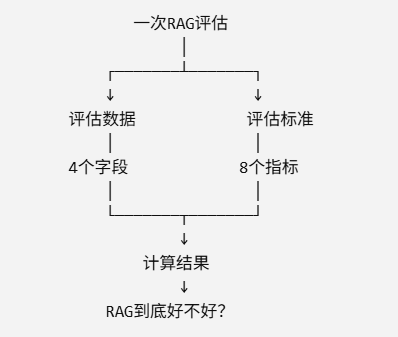

#### 1.3.1 Context Precision（上下文精度） 解决：我找出来的东西准不准

_**Context Precision 用来评价 RAG 检索出来的 Context 的“准确程度”和“排序质量”**_
###### user_input
######      ↓
###### retrieved_contexts

**测什么**：检索返回的文档中，有多少是真正和问题相关的？同时考虑排名——相关文档排得越靠前，分数越高。

**公式**：

$$\text{Context Precision@K} = \frac{\sum_{i=1}^{K} (\text{relevant}_i \times \frac{|\text{relevant in top } i|}{i})}{|\{\text{total relevant documents}\}|}$$

**简化理解**：前K个结果中，相关文档排得越靠前贡献越大（排第1位权重1，排第3位权重1/3）。

**举例**：

* 用户问：“孔子的教育思想有哪些？”
* 检索返回：① 孔子：有教无类、因材施教 ✓ ② 孟子：性善论 × ③ 荀子：性恶论 ×
* 只有①相关且排在第一位 → Context Precision ≈ 1.0 (高)
* 若顺序为：① 孟子 × ② 荀子 × ③ 孔子 ✓，则相关文档排在第3位 → 分数低

**目标**：>= 0.85

##### **_Context Precision 越高，说明 Retriever 返回的 Context 越“精准”，无关内容越少，而且相关内容通常排得越靠前_**

#### 1.3.2 Context Recall（上下文召回率） 解决： 该找的东西有没有漏

**测什么**：Ground Truth 中包含的信息，检索回来的文档覆盖了多少？有没有漏掉关键信息？
###### 标准答案
######    ↓
###### 里面有多少个关键知识点？
######    ↓
###### Retriever 找回来的 Context
######    ↓
###### 这些知识点有多少被覆盖？

**公式**：

$$\text{Context Recall} = \frac{\text{检索文档能支持的 GT 陈述数}}{\text{GT 中总陈述数}}$$

RAGAS 将 Ground Truth（标准答案）拆解为原子陈述，逐一判断能否从检索文档中推断出来。

**举例**：

* 问题: "《学记》提出了哪些教学原则?"
* Ground Truth: "教学相长、豫时孙摩、长善救失、启发诱导" (4条)
* 检索只返回了“教学相长”和“启发诱导”相关内容 → Context Recall ≈ 2/4 = 0.5 (低)

**目标**：>= 0.70

_**与这三个字段存在联系：**_
user_input
retrieved_contexts
reference

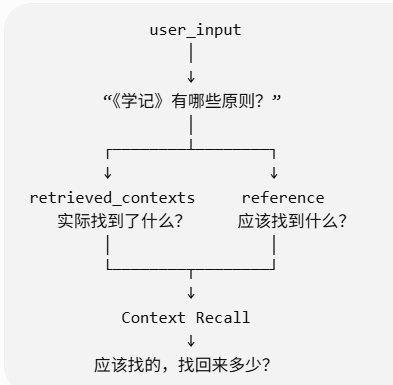

#### 1.3.3 Context Entities Recall（事实上下文召回） 解决：关键的人名、书名、术语、数字等实体有没有被找回来
###### **_Context Recall 解决：标准答案中的完整信息有没有被 Context 覆盖_**

**测什么**：Ground Truth 中出现的实体（人名、地名、术语、数字等），检索回来的文档覆盖了多少？适用于事实密集型场景。

**公式**：

$$\text{Context Entities Recall} = \frac{|\text{RE} \cap \text{RCE}|}{|\text{RE}|}$$

其中 RE = Ground Truth 中的实体集合，RCE = 检索文档中的实体集合。

**举例**：

* 问题: "夸美纽斯有什么贡献?"
* Ground Truth 实体: {夸美纽斯, 大教学论, 班级授课制, 泛智教育, 学年制}
* 检索文档实体: {夸美纽斯, 大教学论, 班级授课制} → 命中3个
* Context Entities Recall = 3/5 = 0.6

**目标**：>= 0.70
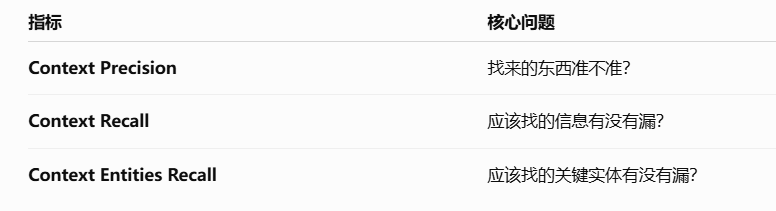

#### 1.3.4 Faithfulness（忠实度 / 反幻觉） **_回答有没有依据找到的资料**_

**_检查 LLM 有没有“根据检索到的资料说话”，有没有自己编造 Context 里没有的事实_**
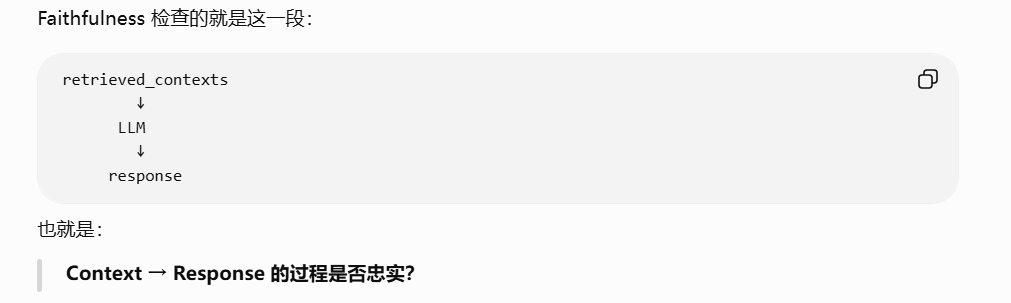
**测什么**：模型回答中每一个事实陈述是否都能从检索文档中找到依据？检测“幻觉”的核心指标。 判断LLM是否乱编造

**公式**：

$$\text{Faithfulness} = \frac{|\text{检索文档能支持的陈述数}|}{|\text{回答中的总陈述数}|}$$

RAGAS 将回答拆解为原子级事实陈述，逐一用检索文档验证。

**举例**：

* 检索文档: "夸美纽斯在《大教学论》中提出班级授课制。"
* 模型回答: "夸美纽斯提出了班级授课制和泛智教育, 被称为教育学之父。"
* 拆解: ①"班级授课制" ✓ ②"泛智教育" ✗ (文档无) ③"教育学之父" ✗ (文档无)
* Faithfulness = 1/3 ≈ 0.33 —— 编造了2个事实

**目标**：>= 0.90

###### _**Context Precision / Recall 是在检查“找资料”的能力；Faithfulness 是在检查“拿资料回答”的能力**_

#### 1.3.5 Response Relevancy（回答相关性 / 切题度）

**测什么**：模型的回答是否紧扣用户问题？有没有答非所问或跑题？  **_回答有没有针对用户的问题_**
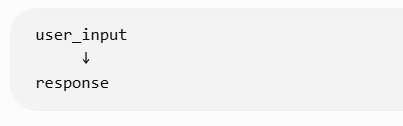

> 注：Python 类名为 `AnswerRelevancy`，文档中称为 Response Relevancy。

**公式**：

$$\text{Response Relevancy} = \frac{1}{N} \sum_{i=1}^{N} \cos(E_{\text{original\_question}}, E_{\text{generated\_question}_i})$$

RAGAS 从模型回答反向生成 N 个问题，计算每个生成问题与原始问题的余弦相似度后取平均。

**举例**：

* 用户问：“教育的本质属性是什么？”
* 回答A：“教育是有目的地培养人的社会活动。”→ 反向问题 = “教育的本质属性是什么？”→ 相似度高
* 回答B：“教育经历了原始、古代、现代三个阶段……”→ 反向问题 = “教育经历了哪些阶段？”→ 相似度低

**目标**：>= 0.88

#### 1.3.6 Noise Sensitivity（噪声敏感度）
###### **_检索结果里出现了“噪声”时，RAG 会不会被这些噪声带偏，产生错误或无依据的回答_**

###### **_**_**_噪声 = Retriever 返回了，但与当前问题无关、或者无法帮助正确回答的信息_**_**_**

**测什么**：系统在利用检索文档时，产生错误回答的频率有多高？噪声敏感度越低，系统越鲁棒。

**公式**：

$$\text{Noise Sensitivity}_{\text{relevant}} = \frac{|\text{回答中的错误陈述数}|}{|\text{回答的总陈述数}|}$$

其中“错误陈述” = 不符合 Ground Truth 或无法归因于相关上下文的陈述。得分越低越好 (0 = 完美)。

**举例**：

* 问题：“LIC 以什么著称？”
* Ground Truth：“LIC 是印度最大的保险公司，1956年成立，管理大规模投资组合。”
* 模型回答：“LIC是最佳保险公司，拥有庞大投资组合，对金融稳定有贡献。”
* 拆解：①“最大保险公司”✓ ②“投资组合”✓ ③“对金融稳定有贡献”✗ (Ground Truth 未提及)
* Noise Sensitivity = 1/3 ≈ 0.333

**目标**：<= 0.10（越低越好）

## 2. 准备被评估的RAG系统和数据集

我们先把上节的RAG系统搬过来。

### 2.1 准备知识库和检索组件

#### 2.1.1 加载文档

**_document可以理解为：_**
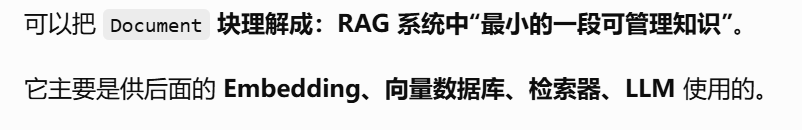

In [6]:
# 加载知识库 — 与上一节的完整示例相同
# RAG 知识库构建中的「文档加载 + 文本切分 + 文档增强」

from langchain_community.embeddings import DashScopeEmbeddings  # 导入 DashScope 的 Embedding 模型
from langchain_core.vectorstores import InMemoryVectorStore # 导入内存向量数据库
from langchain_text_splitters import MarkdownHeaderTextSplitter # 导入 Markdown 标题切分器
from langchain_text_splitters import RecursiveCharacterTextSplitter # 如果某一块内容太长，就继续按照指定的分隔符进行细分
from langchain_core.documents import Document
import os
from dotenv import load_dotenv # 导入 .env 环境变量加载工具

load_dotenv()

# 1. 加载并切分知识笔记（请准备好 ./resources/评估.md 或 中二知识笔记.md）
md_path = "./resources/评估.md"
if not os.path.exists(md_path):
    md_path = "./resources/中二知识笔记.md"

# 读取评估.md文件
with open(md_path, "r", encoding="utf-8") as f:
    docs = f.read()

# 先用md结构切分 按照标题切分
headers_to_split_on = [
    ("#", "Header 1"),
    ("##", "Header 2"),
    ("###", "Header 3"),
]
# 创建标题切分器
markdown_splitter = MarkdownHeaderTextSplitter(headers_to_split_on)
# 正式进行第一次切分
chunks = markdown_splitter.split_text(docs)

# 创建递归（二级）字符切分器
recursive_splitter = RecursiveCharacterTextSplitter(
    chunk_size=200,
    chunk_overlap=0,
    separators=["\n\n", "\n", "。"]  # 优先级从高到低
)
# 创建一个空列表，用来保存经过加载、切分、二次切分、标题处理等预处理之后的最终 Document 块。
ds = []
# 初始文档编号
idx = 1

# 定义方法，作用是给文档内容拼上三级标题和id  对每个切分后的 Document 做“二次加工”：把标题信息补回正文，并给这个文档块分配一个唯一 ID
def handle_doc_header(doc: Document):
    # 使用函数外部定义的 idx 变量，而不是在函数内部重新创建一个 idx
    global idx
    # 获取当前文档的元数据
    m = doc.metadata
    # 优先获取 Header 3，如果没有 Header 3，就获取 Header 2，如果连 Header 2 都没有，就使用空字符串
    header3 = m.get("Header 3", m.get("Header 2", ""))
    # 修改文档正文内容
    doc.page_content = f"### {header3}\n{doc.page_content}"
    # 给当前文档设置一个唯一 ID
    doc.id = f"doc_{idx}"
    # 每处理一个文档增加1
    idx = idx + 1
    # 返回处理后的文档
    return doc

# 遍历chunks中的每一个文档，判断大小，如果超过了200，再用递归大小切分（用字符切分器切分）
for doc in chunks:
    # 获取文档内容
    content = doc.page_content
    # 判断文档是否超过200个字符
    if len(content) > 200:
        # 超过之后继续递归切分
        sub_docs = recursive_splitter.split_documents([doc])
        # 把切分后的文档处理后加入 ds extend 把多个子文档分别加入 ds 用到了handle_doc_header(d)方法
        ds.extend(handle_doc_header(d) for d in sub_docs)
    else:
        # append 把整个列表作为一个元素加入
        ds.append(handle_doc_header(doc))

for chunk in ds[:3]:  # 仅打印前几个示例
    print(len(chunk.page_content))
    print(chunk.id)
    print(chunk)
    print("=" * 60)

print(f"共切分出 {len(ds)} 个文档块")

188
doc_1
page_content='### （一）孔子主要思想
**教育对象**：有教无类。主张人人都应该接受教育，打破了贵族对教育的垄断。  
**教育目的**：培养士和君子。君子应具备仁、智、勇等品德。  
**教学原则**：
1. 因材施教：根据学生的不同特点采取不同的教学方法。
2. 启发诱导：不愤不启，不悱不发。
3. 学思结合：学而不思则罔，思而不学则殆。
4. 谦虚笃实：知之为知之，不知为不知。' metadata={'Header 1': '教育学知识笔记（教资考点）', 'Header 2': '一、中国古代教育思想', 'Header 3': '（一）孔子主要思想'}
77
doc_2
page_content='### （一）孔子主要思想
**教学内容**：六经（诗、书、礼、易、乐、春秋），重视道德教育。  
**教育作用**：教育可以改变人的命运，促进社会和谐。' metadata={'Header 1': '教育学知识笔记（教资考点）', 'Header 2': '一、中国古代教育思想', 'Header 3': '（一）孔子主要思想'}
142
doc_3
page_content='### （二）孟子主要思想
**人性论**：人性本善。人先天具有仁、义、礼、智四个“善端”。  
**教育作用**：发扬善端，培养道德完人，得天下英才而教育之。  
**教学原则**：循序渐进，专心有恒。  
**教育目的**：培养“大丈夫”人格，富贵不能淫，贫贱不能移，威武不能屈。' metadata={'Header 1': '教育学知识笔记（教资考点）', 'Header 2': '一、中国古代教育思想', 'Header 3': '（二）孟子主要思想'}
共切分出 26 个文档块


#### 2.1.2 准备知识库和工具

**_总结：_**
**_BM25 建立索引和向量检索建立索引，本质目的相同——都是为了让后续能够快速、高效地从大量知识块中找到相关内容；但两者建立索引的原理和后续检索的匹配方式不同_**

In [7]:
# ds 文档切片之后，正式进入“向量化 + 建立向量检索库”

# 2. 向量化（DashScope Embedding） 负责把文字变成向量
embeddings = DashScopeEmbeddings(
    model="text-embedding-v3",
    dashscope_api_key=os.getenv("DASHSCOPE_API_KEY")
)
# 创建一个向量数据库 内存中的向量数据库
# 使用向量检索 稠密检索
vectorstore = InMemoryVectorStore(embeddings)
# 把 ds 加入向量数据库 把切片向量化并存进去
vectorstore.add_documents(ds)
# 把 VectorStore 转换成一个“检索器”
# retriever 可以根据用户问题，从向量知识库里面找相关知识的搜索器 把 VectorStore 包装成一个 Retriever 检索器
retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

print(f"知识库已就绪: {len(ds)} 个文档切片")

# 上述部分完成了： ① 知识库内容的向量化 + ② 向量数据库构建 + ③ 检索器 Retriever 的创建

知识库已就绪: 26 个文档切片


In [8]:
# 3. BM25 稀疏检索 用户问了一个问题，如何从大量文档中找到文字匹配度最高的几个文档
import bm25s # 导入BM25
import spacy_pkuseg as pkuseg  # 导入中文分词工具

# 创建中文分词器
seg = pkuseg.pkuseg()

# 创建 BM25 索引；如果索引已经存在，就直接加载，而不是重新计算
# metadata_corpus 代表语料库 创建语料库 先把要搜索的数据准备好，再给这些数据建立一个方便快速搜索的结构
def create_bm25_index(metadata_corpus, index_path="./db/my_index2.bm25", k1=1.5, b=0.75):
    if os.path.exists(index_path):
        print(f"索引文件已存在，正在加载: {index_path}")
        # 从硬盘中加载之前已经建立好的 BM25 索引以及语料库加载进来
        _retriever = bm25s.BM25.load(index_path, load_corpus=True)
    else:
        print(f"未找到索引文件，正在创建新索引...")
        # 对语料进行分词 如果索引不存在，则先对所有文档内容进行分词处理 seg.cut()：将每篇文档的文本切分成词语列表
        corpus_tokens = [seg.cut(doc["content"]) for doc in metadata_corpus]
        # 基于原始文档创建索引库，将来检索出来的也是原始文档
        _retriever = bm25s.BM25(k1=k1, b=b, corpus=metadata_corpus)
        # 创建索引
        _retriever.index(corpus_tokens)
        # 保存到本地
        _retriever.save(index_path)
        print(f"索引已保存至: {index_path}")
    return _retriever

# 准备语料库，文档来源ds
metadata_corpus = [{"id": doc.id, "content": doc.page_content} for doc in ds]
# 创建检索器
bm25_retriever = create_bm25_index(metadata_corpus)

# 定义检索函数 真正执行检索的地方
def bm25_search(query: str, k: int = 3):
    query_tokens = [seg.cut(query)]
    results, scores = bm25_retriever.retrieve(query_tokens, k=k)
    return [(results[0, i], scores[0, i]) for i in range(results.shape[1])]


print("BM25 检索器已就绪")

索引文件已存在，正在加载: ./db/my_index2.bm25
BM25 检索器已就绪


In [9]:
# 把向量检索和 BM25 检索得到的多个结果列表，融合成一个最终的排序结果
# 4. RRF 融合
# 核心作用：通过 doc_id 判断是不是同一个文档；如果是同一个文档，就把它在不同检索器中的排名贡献加起来
# 一个文档同时被两个检索器认为相关，它的综合排名就会比较靠前

# ranked_lists：多个检索器返回的排序结果
def reciprocal_rank_fusion(ranked_lists, k=60):
    # 创建空字典 负责记录：每个文档经过多个检索器之后，最终获得多少 RRF 分数
    rrf_scores = {}
    # 创建空字典 负责保存 文档ID → 文档本身
    results = {}
    # 依次处理每一个检索器返回的结果列表
    for rank_list in ranked_lists:
        # 遍历当前检索结果，并同时拿到“排名”和“文档”
        for rank, doc in enumerate(rank_list, start=1):
            # 从当前文档拿出它的唯一ID
            doc_id = doc["id"]

            # rrf_scores.get(doc_id, 0)代表：如果这个文档之前已经获得过 RRF 分数，就把之前的分数取出来；如果还没有，就从 0 开始
            rrf_scores[doc_id] = rrf_scores.get(doc_id, 0) + 1.0 / (k + rank)
            results[doc_id] = doc
    # 按照 RRF 得分从高到低重新排序  降序排列，分数最高的排前面
    sorted_docs = sorted(rrf_scores.items(), key=lambda x: x[1], reverse=True)
    # 根据刚才排好的文档 ID，把完整的文档重新取出来，并按照 RRF 排名返回
    return [results[doc_id] for doc_id, score in sorted_docs]


print("RRF 融合已就绪")

RRF 融合已就绪


In [10]:
# 5. Cross-Encoder 重排序（可选，需要 GPU 或较长下载时间）
# import torch
# from sentence_transformers import CrossEncoder

# 加载 Cross-Encoder 模型
# cross_model = CrossEncoder(
#     "Qwen/Qwen3-Reranker-0.6B",
#     device="cuda" if torch.cuda.is_available() else "cpu"
# )

# RRF 负责把多个检索器的结果“合并排序”，Cross-Encoder 负责把融合后的候选文档拿出来，逐个和用户问题进行更精确的语义匹配，然后重新排序，选出最终最相关的 Top-K

# 未加载重排序模型时保持 None，函数会自动退回"直接取前 top_k"
# 当前没有加载 Cross-Encoder 模型
cross_model = None

# 定义重排序函数
def cross_encoder_rerank(query: str, docs, top_k: int = 3):
    """若未加载 cross_model，则直接返回前 top_k"""  # top_k代表 检索器从知识库中找到相关文档后，只保留排名最靠前的 K 个知识块
    if cross_model is None:
        # 只是直接把 RRF 排在前面的 Top 3 返回
        return docs[:top_k]
    # 加载了模型，工作的地方
    scores = cross_model.predict([(query, doc["content"]) for doc in docs])
    # 遍历模型给出的每一个分数
    for i, s in enumerate(scores):
        docs[i]["score"] = float(s)
    # 按照 Cross-Encoder 分数重新排序
    sorted_docs = sorted(docs, key=lambda x: x["score"], reverse=True)
    # 只保留 Cross-Encoder 分数大于 0 的文档
    positive_docs = [doc for doc in sorted_docs if doc["score"] > 0]
    # 最多返回 top_k 个正分文档
    return positive_docs[:min(top_k, len(positive_docs))]


print("Cross-Encoder 函数已定义（模型按需加载）")
print("\n所有检索组件准备完成！")

Cross-Encoder 函数已定义（模型按需加载）

所有检索组件准备完成！


### 2.2 创建Agent

In [11]:
# 构建 Agent —— 与上一节完整示例相同
# 向量检索 + BM25 + RRF + Cross-Encoder 真正封装成一个 Agent 可以调用的知识库工具
from langchain.tools import tool  #把普通python函数包装成Agent能够调用的工具
from langchain.agents import create_agent  #创建一个Agent

# 把整个混合检索流程封装起来
def retrieve_docs(query: str, top_k: int):
    """混合检索：稠密 + 稀疏 + RRF + CrossEncoder"""
    # 1. 稠密检索
    vector_results = vectorstore.similarity_search(query, k=top_k)
    # 2. 稀疏检索 BM25
    bm25_results_list = bm25_search(query, k=top_k)
    if not vector_results or not bm25_results_list:
        return []
    # 3. RRF 融合
    # 把向量检索结果转换成统一格式
    vector_rs = [{"id": doc.id, "content": doc.page_content} for doc in vector_results]
    # 把BM25结果取出来
    bm25_rs = [doc for doc, _ in bm25_results_list]
    rrf_results = reciprocal_rank_fusion([vector_rs, bm25_rs])
    # 4. Cross-Encoder 重排序
    return cross_encoder_rerank(query, rrf_results, top_k)


# tool 内部顺手把检索结果存下来，供评估时提取 context，避免检索两次
# 把 Agent 检索到的知识块暂时保存下来，后面做评估的时候可以直接取出来
contexts_store = {}


@tool
def search_knowledge_base(query: str) -> str:
    """搜索知识库，获取教育学、名人等的知识。需要查找资料时使用。"""
    # 调用检索流程 每次 Agent 调用这个工具时，执行完整的混合检索，并最终返回 Top 5 文档
    final_docs = retrieve_docs(query, 5)
    if not final_docs:
        return "未找到相关文档"

    # 顺手存 context，评估取用（简化：用 query 作为 key）
    cs = contexts_store.get(query, [])
    cs.extend([doc["content"] for doc in final_docs])
    contexts_store[query] = list(set(cs))

    return "\n\n".join(doc["content"] for doc in final_docs)


rag_agent = create_agent(
    model="deepseek-chat",
    tools=[search_knowledge_base],
    system_prompt="""
你是一个教资考试答题助手。你必须严格遵守以下规则：

1. 有关教资的问题**只能**调用`search_knowledge_base`工具来查阅相关文档，根据文档信息回答问题
2. **禁止**添加任何你自己的知识、理解或推断
3. **禁止**扩展、举例或给出建议
4. 如果参考文档中没有相关信息，直接回复"根据提供的资料，无法回答此问题"
5. 回答要简洁，直接引用原文，不要改写或总结
""",
)

print("RAG Agent 创建完成！（混合检索：稠密+BM25+RRF+CrossEncoder）")

RAG Agent 创建完成！（混合检索：稠密+BM25+RRF+CrossEncoder）


### 2.3 准备数据集

数据集的每条数据包含4部分：

* `user_input`：问题
* `reference`：标准答案
* `retrieved_contexts`：召回的文档
* `response`：RAG系统生成的答案

前两个需要提前提供好，后两个则是需要调用RAG系统生成。

在资料的 resources 目录可提供一份评估问题 JSON（含 question / ground_truth），然后循环调用 RAG 系统生成 retrieved_contexts 与 response。


##### **_准备一批“标准题目”，然后让你的 RAG Agent 一道一道回答，把“它查到了什么”和“它最终回答什么”保存下来，最后形成一个可以用于 RAG 评估的数据集_**

In [12]:
# 收集 Agent 回答和检索上下文，构建 ragas Dataset
# 真实运行 RAG Agent后得到的评估数据集

# 它是在自动运行一批测试问题，让 RAG Agent 逐题回答，同时记录 Agent 的回答、实际检索到的上下文以及标准答案，最后构建成一个用于 RAGAS 评估的数据集

import json
import time
from ragas import Dataset # Ragas 专门用来保存评估样本的“数据集容器

# 定义创建数据集的函数
def create_dataset():
    """创建dataset，先尝试本地加载，如果没有则重新生成"""

    # 1. 创建 ragas Dataset  创建一个数据集 name="rag_eval"
    # 注意：local/csv 后端会把列表字段（retrieved_contexts）压成字符串，重载后类型丢失，
    # 导致评估指标把字符串当字符逐个处理（一次跑几百次调用）。改用 local/jsonl 后端保存列表。
    dataset = Dataset(name="rag_eval", backend="local/jsonl", root_dir="./experiments")
    if os.path.exists("./experiments/datasets/rag_eval.jsonl"):
        # 尝试读取本地数据
        dataset.reload()
        # 如果有数据，直接返回，没有则重新生成数据集
        if len(dataset) > 0:
            print(f"加载了 {len(dataset)} 个测试数据集，不再重新生成")
            return dataset

    # 2. 加载评估问题 预先准备的评估题目和标准答案
    eval_path = "./resources/ragas_eval_dataset.json"
    if not os.path.exists(eval_path):
        # 若无现成 JSON，用示例数据演示
        eval_data = [
            {
                "question": "孔子的教育思想有哪些？",
                "ground_truth": "孔子主张有教无类，提出因材施教、启发诱导、学思结合、谦虚笃实四大教学原则。教育目的是培养士和君子。"
            },
            {
                "question": "孟子和荀子的人性论观点有什么不同？",
                "ground_truth": "孟子主张性善论，认为人先天具有仁、义、礼、智四个善端；荀子主张性恶论，认为善德是后天习得的，强调化性起伪，重视教育的作用。"
            },
            {
                "question": "《学记》提出了哪些教学原则？",
                "ground_truth": "教学相长、豫时孙摩、长善救失、启发诱导。"
            },
            {
                "question": "夸美纽斯有什么贡献？",
                "ground_truth": "夸美纽斯著有《大教学论》，提出泛智教育、班级授课制和学年制，被称为教育学之父。"
            },
        ]
        print("使用内置示例评估问题")
    else:
        with open(eval_path, "r", encoding="utf-8") as f:
            eval_data = json.load(f)
        print(f"加载了 {len(eval_data)} 个评估问题")

    # 3. 调用 Agent，生成 response 和 context
    # 每次 Agent 调用后的等待时间（秒），避免触发模型提供商限流
    REQUEST_DELAY = 1

    print(f"开始收集回答和上下文（共 {len(eval_data)} 题，间隔 {REQUEST_DELAY}s）...")
    print("-" * 50)

    # 收集 Agent 实际使用的检索上下文。 收集 Agent 实际运行产生的上下文和回答，再和原来的评估问题、标准答案组合成评估数据集
    # 注意：模型调用工具时可能改写/截断问题（如把"孔子的教育思想有哪些？"传成"孔子的教育思想"），
    # 所以不能只按原始问题取，要从工具调用参数里拿到真实 query。

    # 这一块代码的作用：这一块代码不是直接把 Agent 生成的上下文与评估数据进行比较，而是先把 Agent 实际检索到的上下文、Agent 的回答，与预先准备的评估问题和标准答案收集到一起，构建成完整的 RAGAS Dataset，供后续 RAGAS 进行比较和评分

    # 根据用户问题 query 和 Agent 运行过程中的 messages，找出 Agent 实际检索到并使用的文档内容
    def collect_contexts(query, messages):
        # 先根据原始问题获取 Context
        contexts = list(contexts_store.get(query, []))
        # 遍历 Agent 执行过程中产生的每一条消息
        for msg in messages:
            # 从消息中寻找工具调用
            for tc in getattr(msg, "tool_calls", None) or []:
                # 获取工具调用参数
                args = tc.get("args", {}) if isinstance(tc, dict) else getattr(tc, "args", {}) or {}
                # 获取 Agent 实际传给工具的 Query
                real_query = args.get("query")
                # 判断真实 Query 是否存在
                if real_query:
                    # 根据真实 Query 获取 Context
                    contexts.extend(contexts_store.get(real_query, []))
        # 去重并保持顺序
        seen, out = set(), []
        for c in contexts:
            if c not in seen:
                seen.add(c)
                out.append(c)
        return out

    for i, item in enumerate(eval_data):
        query = item["question"]

        # 调用 Agent —— 内部 search_knowledge_base tool 会将检索结果存入 contexts_store
        response = rag_agent.invoke(
            {"messages": [{"role": "user", "content": query}]},
        )
        answer = response["messages"][-1].content

        # 从 tool 的 store 中取 context（一次检索，不重复）
        contexts = collect_contexts(query, response["messages"])
        # 兜底：万一 Agent 没有调用工具，直接用混合检索拿上下文，保证评估数据完整
        if not contexts:
            contexts = [d["content"] for d in retrieve_docs(query, 5)]

        # 写入数据集 dataset.append({...}) 是把本次测试的一整条评估样本组装起来；其中既有 Agent 运行产生的数据，也有 预先准备好的评估数据
        dataset.append({
            "user_input": query,
            "response": answer,
            "retrieved_contexts": contexts,
            "reference": item["ground_truth"],
        })

        print(f"[{i + 1}/{len(eval_data)}] {query[:40]}... ✓ (contexts: {len(contexts)}条)")

        # 等待一会儿再发下一个请求，避免触发限流
        if i < len(eval_data) - 1:
            time.sleep(REQUEST_DELAY)

    dataset.save()
    print(f"\n评估数据集已保存: {len(eval_data)} 个样本 -> ./experiments/")
    return dataset


# 调用函数，创建dataset
dataset = create_dataset()

加载了 4 个测试数据集，不再重新生成


## 3. RAGAS 评估

RAGAS 需要 LLM 和 Embedding 模型作为评判器（Judge），推荐用强模型以确保评估可靠性。最新版本中默认是基于OpenAI的客户端协议，虽然可配置但也仅支持国外的几种模型协议。所以我们需要手动初始化。

### 3.1 准备模型

由于RAGAS默认支持OpenAI的客户端协议，所以我们不能用LangChain来初始化，而是改用OpenAI的客户端。

In [13]:
# 新 API：@experiment 装饰器 + 标准指标
# 给 RAGAS 准备“评估模型”——一个负责判断和打分的 LLM，以及一个负责计算语义相似度的 Embedding 模型

from ragas.llms import llm_factory # 导入 RAGAS 的工具 作用：把一个 LLM 客户端包装成 RAGAS 可以使用的评估 LLM
from ragas.embeddings.base import embedding_factory # 把 Embedding 客户端包装成 RAGAS 可以使用的向量模型
from openai import AsyncOpenAI # 导入 OpenAI 官方 Python SDK 的异步客户端 使用 OpenAI SDK ≠ 必须使用 OpenAI 模型

# 这里用的是OpenAI的官方SDK，连的是DeepSeek，当然你也可以用本地模型
llm_client = AsyncOpenAI(
    api_key=os.getenv("DEEPSEEK_API_KEY"),
    base_url=os.getenv("DEEPSEEK_BASE_URL", "https://api.deepseek.com")
)

# 这里用的是OpenAI的官方SDK，但连的还是免费的阿里云百炼，当然你也可以用本地模型
embedding_client = AsyncOpenAI(
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url=os.getenv("DASHSCOPE_BASE_URL", "https://dashscope.aliyuncs.com/compatible-mode/v1")
)

# 文本推理模型
evaluator_llm = llm_factory(
    model="deepseek-chat", client=llm_client, max_tokens=8192
)

# 向量模型
evaluator_embeddings = embedding_factory(
    model="text-embedding-v3", client=embedding_client
)

print("评估用 LLM 与 Embedding 已就绪")

评估用 LLM 与 Embedding 已就绪


### 3.2 指标评估

准备好了模型，接下来就可以开始评估了，我们先进行一次调用，做个简单测试。

我们随意获取一条数据集：

In [14]:
# 查看一条样本
print(dataset.__getitem__(min(3, len(dataset) - 1)))

{'user_input': '夸美纽斯有什么贡献？', 'response': '根据知识库中的资料，夸美纽斯的贡献如下：\n\n夸美纽斯是捷克教育家，被誉为"教育学之父"。\n\n**主要著作**：《大教学论》。\n\n**核心主张**：\n1. **泛智教育**：主张把一切知识教给一切人。\n2. **班级授课制**：系统论述班级授课制，提出学年制。\n3. **教育适应自然**：教育应遵循自然秩序和儿童发展规律。\n4. **直观教学**：强调感官经验在认识中的作用。\n\n此外，他提出的**学年制**是指把一年分为若干学期，规定统一的开学、放假时间。', 'retrieved_contexts': ['### （一）夸美纽斯主要贡献\n夸美纽斯是捷克教育家，被誉为“教育学之父”。  \n**主要著作**：《大教学论》。  \n**核心主张**：\n1. **泛智教育**：主张把一切知识教给一切人。\n2. **班级授课制**：系统论述班级授课制，提出学年制。\n3. **教育适应自然**：教育应遵循自然秩序和儿童发展规律。\n4. **直观教学**：强调感官经验在认识中的作用。', '### （四）巴班斯基的教育理论\n巴班斯基是苏联教育家，提出**教学过程最优化**理论。  \n**核心内容**：\n1. 在一定条件下，用最少的时间和精力，取得最好的教学效果。\n2. 强调综合规划教学任务、优选教学内容和教学方法。\n3. 注重教学过程中的反馈和调控。', '### （五）课程现代化的三大代表人物\n1. **布鲁纳**（结构主义课程论）：强调学科基本结构，提倡发现学习。\n2. **瓦·根舍因**（范例教学）：通过典型范例掌握学科本质。\n3. **赞科夫**（发展性教学）：强调高难度、高速度、理论知识起主导作用等五条教学原则。  \n---', '### （二）教师专业发展\n教师专业发展的阶段通常包括：关注生存阶段、关注情境阶段、关注学生阶段。', '### （一）夸美纽斯主要贡献\n**学年制**：把一年分为若干学期，规定统一的开学、放假时间。'], 'reference': '夸美纽斯著有《大教学论》，提出泛智教育、班级授课制和学年制，被称为教育学之父。'}


In [15]:
# 从已经生成好的 RAGAS dataset 中取出一条测试数据，然后查看这条数据里的“问题、Agent回答、检索Context、标准答案
# 进行数据检查/查看步骤

# 从 dataset 中按照索引取出一条数据
row = dataset.__getitem__(min(3, len(dataset) - 1))
# 获取用户问题
user_input = row.get("user_input")
# 获取Agent的回答
response = row.get("response")
# 获取检索到的context RAG Agent 实际从知识库检索出来的知识块
retrieved_contexts = row.get("retrieved_contexts")
# 获取标准答案 评估数据中预先准备好的标准答案
reference = row.get("reference")

print("user_input:", user_input)
print("reference:", reference[:80] if reference else None, "...")

user_input: 夸美纽斯有什么贡献？
reference: 夸美纽斯著有《大教学论》，提出泛智教育、班级授课制和学年制，被称为教育学之父。 ...


In [16]:
# 开始使用RAGS对RAG系统进行评估，并计算6个核心指标
# 把RAGAS的6个评估指标导入进来，6个核心指标（从 collections 导入）
from ragas.metrics.collections import (
    Faithfulness,  # 忠实度
    AnswerRelevancy,  # 回答相关性
    ContextPrecision,  # 上下文精度
    ContextEntityRecall,  # 上下文实体召回
    NoiseSensitivity,  # 噪声敏感度
    ContextRecall  # 上下文召回
)

import asyncio
import time

# DeepSeek 等 API 偶尔会卡顿/超时，这里给每个指标加超时保护，超时或失败后自动重试一次
async def run_metric(name, coro_factory, timeout=180):
    for attempt in range(1, 3):
        try:
            t0 = time.time()
            result = await asyncio.wait_for(coro_factory(), timeout=timeout)
            print(f"运行完成{name}评估,score: {result},用时 {time.time()-t0:.1f}s", flush=True)
            return result
        except asyncio.TimeoutError:
            print(f"{name} 第{attempt}次调用超过 {timeout}s，正在重试...", flush=True)
        except Exception as e:
            print(f"{name} 第{attempt}次调用失败：{type(e).__name__}: {str(e)[:120]}，正在重试...", flush=True)
    raise RuntimeError(f"{name} 连续两次调用失败/超时")

print(f"========开始评估：input:{user_input}===========")

# ---- 检索阶段指标 ---- 主要评价：RAG 有没有找到好的资料

# 前面准备好的 evaluator_llm 作为评委
cp = ContextPrecision(llm=evaluator_llm)
# 让RAGAS判断 检索出来的 Context 中，有多少是真正有用的
cp_result = await run_metric("context precision", lambda: cp.ascore(
    user_input=user_input,
    reference=reference,
    retrieved_contexts=retrieved_contexts,
))
print(f"进度1/6\n")

cr = ContextRecall(llm=evaluator_llm)
# 标准答案中需要的信息，你的检索有没有找全
cr_result = await run_metric("context recall", lambda: cr.ascore(
    user_input=user_input,
    reference=reference,
    retrieved_contexts=retrieved_contexts,
))
print(f"进度2/6\n")

cer = ContextEntityRecall(llm=evaluator_llm)
# 标准答案中的关键实体/信息点，有多少被检索上下文覆盖到了
cer_result = await run_metric("ContextEntityRecall", lambda: cer.ascore(
    reference=reference,
    retrieved_contexts=retrieved_contexts,
))
print(f"进度3/6\n")

# ---- 生成阶段指标 ----  Agent 根据这些资料，回答得怎么样
faith = Faithfulness(llm=evaluator_llm)
# Agent 的回答是不是有 Context 依据
faith_result = await run_metric("Faithfulness", lambda: faith.ascore(
    user_input=user_input,
    response=response,
    retrieved_contexts=retrieved_contexts,
))
print(f"进度4/6\n")

# Agent 有没有回答用户真正问的问题
ar = AnswerRelevancy(llm=evaluator_llm, embeddings=evaluator_embeddings)
ar_result = await run_metric("AnswerRelevancy", lambda: ar.ascore(
    user_input=user_input,
    response=response,
))
print(f"进度5/6\n")

ns = NoiseSensitivity(llm=evaluator_llm)
ns_result = await run_metric("NoiseSensitivity", lambda: ns.ascore(
    user_input=user_input,
    response=response,
    reference=reference,
    retrieved_contexts=retrieved_contexts,
))
print(f"进度6/6\n")
print(f"========================评估完成==========================")

========开始评估：input:夸美纽斯有什么贡献？===========
运行完成context precision评估,score: MetricResult(value=0.9999999999),用时 13.3s
进度1/6

运行完成context recall评估,score: MetricResult(value=1.0),用时 3.3s
进度2/6

运行完成ContextEntityRecall评估,score: MetricResult(value=0.9999999983333333),用时 5.1s
进度3/6

运行完成Faithfulness评估,score: MetricResult(value=1.0),用时 7.4s
进度4/6

运行完成AnswerRelevancy评估,score: MetricResult(value=0.9835023817112765),用时 9.8s
进度5/6

运行完成NoiseSensitivity评估,score: MetricResult(value=0.5454545454545454),用时 51.1s
进度6/6

========================评估完成==========================


评估时间会比较长，耐心等待后，就能看到类似结果：

```
========开始评估：input:孟子和荀子的人性论观点有什么不同？===========
运行完成context precision评估,score: MetricResult(value=0.99999999995),进度1/6
运行完成context recall评估,score: MetricResult(value=1.0),进度2/6
运行完成ContextEntityRecall评估,score: MetricResult(value=0.333...),进度3/6
运行完成Faithfulness评估,score: MetricResult(value=1.0),进度4/6
运行完成AnswerRelevancy评估,score: MetricResult(value=0.998...),进度5/6
运行完成NoiseSensitivity评估,score: MetricResult(value=0.0),进度6/6
========================评估完成==========================
```

### 3.3 定义 experiment

新版的RAGAS中，把评估任务称为 experiment，也就是实验。之所以叫这个名字，是因为所有的实验数据都是流痕的，可追溯的，不像之前老版本中是黑盒打分。

创建实验其实就是定义函数，但要用 `@experiment` 装饰器。

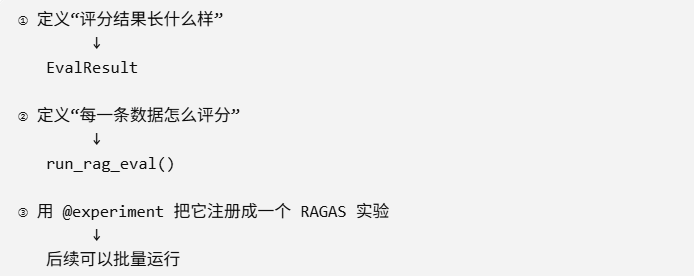

In [17]:
# 把前面“手动评估一条数据”的代码，封装成一个标准化的 RAGAS 实验函数，让它可以对 Dataset 中的每一行数据自动执行评估，并最终返回结构化的评分结果
# 新 API：@experiment 装饰器 + 标准指标
from ragas import experiment  # 把下面定义的普通 Python 函数变成一个 RAGAS 实验函数
from pydantic import BaseModel # 定义结构化的数据格式
import asyncio
import time


# 定义实验结果模型 规定每一次实验最终要输出什么
class EvalResult(BaseModel):
    context_recall: float
    faithfulness: float


# 与 3.2 相同的超时重试保护，防止个别指标调用卡住
async def run_metric(name, coro_factory, timeout=180):
    for attempt in range(1, 3):
        try:
            t0 = time.time()
            result = await asyncio.wait_for(coro_factory(), timeout=timeout)
            print(f"完成{name}评估, {time.time()-t0:.1f}s", flush=True)
            return result
        except asyncio.TimeoutError:
            print(f"{name} 第{attempt}次超时，正在重试...", flush=True)
        except Exception as e:
            print(f"{name} 第{attempt}次失败：{type(e).__name__}: {str(e)[:120]}，正在重试...", flush=True)
    raise RuntimeError(f"{name} 连续两次失败/超时")


# 定义实验：逐行评分
@experiment(experiment_model=EvalResult)
async def run_rag_eval(row):
    # 先把评估的数据准备好
    user_input = row.get("user_input")
    reference = row.get("reference")
    retrieved_contexts = row.get("retrieved_contexts")
    response = row.get("response")

    print(f"开始评估：input:{user_input} , 进度0/2")

    # ---- 检索阶段指标 ----
    cr = ContextRecall(llm=evaluator_llm)
    cr_result = await run_metric("context recall", lambda: cr.ascore(
        user_input=user_input,
        reference=reference,
        retrieved_contexts=retrieved_contexts,
    ))
    print(f"完成cr_result评估 , 进度1/2")

    # ---- 生成阶段指标 ----
    faith = Faithfulness(llm=evaluator_llm)
    faith_result = await run_metric("Faithfulness", lambda: faith.ascore(
        user_input=user_input,
        response=response,
        retrieved_contexts=retrieved_contexts,
    ))
    print(f"完成faith_result评估 , 进度2/2")

    # 封装所有结果
    return EvalResult(
        context_recall=cr_result.value,
        faithfulness=faith_result.value
    )


print("实验函数已定义")
print(f"结果模型字段: {list(EvalResult.model_fields.keys())}")

实验函数已定义
结果模型字段: ['context_recall', 'faithfulness']


### 3.4 批量评估

接下来就是跑评估实验了，这个过程非常长，需要耐心等待。

为了节省时间，我们从 dataset 中随机抽取 10% 作为测试的数据集。

**3.2 3.3 3.3之间的关系**

###### **_3.2 指标评估
######     ↓
###### 拿 1 条数据试跑，确认指标能正常工作
######     ↓
###### 3.3 定义 experiment
######     ↓
###### 把“怎么评估一条数据”封装成标准实验函数
######     ↓
###### 3.4 批量评估
######     ↓
###### 把这个实验函数应用到很多条数据_**

In [18]:
# 为了节省时间，我们从dataset中随机抽取 10%作为测试的数据集
train_dataset, test_dataset = dataset.train_test_split(test_size=0.1)
print(test_dataset)  # Dataset(name=rag_eval_test, len=...)

Dataset(name=rag_eval_test,  len=1)


In [19]:
# 把数据集的评估name设定与原来一致，这样就会保存到dataset一样的目录，方便查看
tds = Dataset.from_pandas(
    test_dataset.to_pandas(),
    name="rag_eval",
    backend="local/jsonl",
    root_dir="./experiments"
)

# 3.4 依赖 3.3 定义的 run_rag_eval；若没有先运行 3.3，给出明确提示
if "run_rag_eval" not in globals():
    raise RuntimeError("请先运行 3.3（定义 run_rag_eval 的单元格），再运行本单元格")

# 开始评估 使用run_rag_eval
import asyncio
import time

# 加超时保护：批量评估依赖 API，偶尔会卡顿，超时后自动重试一次
async def _run_experiment_with_retry(timeout=600):
    for attempt in range(1, 3):
        try:
            t0 = time.time()
            result = await asyncio.wait_for(
                run_rag_eval.arun(tds, name="rag_baseline"),
                timeout=timeout,
            )
            print(f"批量评估完成，用时 {time.time()-t0:.1f}s", flush=True)
            return result
        except asyncio.TimeoutError:
            print(f"批量评估超过 {timeout}s，正在重试一次...", flush=True)
        except Exception as e:
            print(f"批量评估失败：{type(e).__name__}: {str(e)[:150]}，正在重试一次...", flush=True)
    raise RuntimeError("批量评估连续两次失败/超时")

results = await _run_experiment_with_retry()

# 查看结果
print("=" * 60)
print("RAGAS 评估报告")
print("=" * 60)
print()
print(f"\n实验记录已保存至: ./experiments/experiments/rag_baseline.jsonl")

Running experiment:   0%|          | 0/1 [00:00<?, ?it/s]

开始评估：input:夸美纽斯有什么贡献？ , 进度0/2
完成context recall评估, 3.3s
完成cr_result评估 , 进度1/2
完成Faithfulness评估, 7.3s


Running experiment: 100%|██████████| 1/1 [00:10<00:00, 10.66s/it]

完成faith_result评估 , 进度2/2
批量评估完成，用时 10.7s
RAGAS 评估报告


实验记录已保存至: ./experiments/experiments/rag_baseline.jsonl


运行结果示例：

```
Running experiment: 100%|██████████| 4/4 [00:14<00:00,  3.65s/it]
============================================================
RAGAS 评估报告
============================================================

实验记录已保存至: ./experiments/rag_baseline/
```

### 3.5 评估结果解读

| 指标 | 发现问题 | 优化方向 |
|------|----------|----------|
| Faithfulness 低 | 模型在编造，没有基于文档回答 | 加强系统提示、降低 temperature |
| Context Precision 低 | 检索返回了无关内容（噪声多） | 优化 chunk_size、加入 Query Rewriting |
| Context Recall 低 | 需要的信息没有检索到（缺信息） | 调整 embedding 模型、增大 k、加入 Hybrid Search |
| Context Entities Recall 低 | 关键实体（人名、术语、数字）未覆盖 | 加入 BM25 关键词检索、优化 chunk 策略 |
| Answer Relevancy 低 | 模型回答跑题了 | 优化 Prompt、限制回答范围 |
| Noise Sensitivity 高 | 噪声文档导致回答出错 | 加入 Cross-Encoder 重排序、提升检索精度 |

> **注意**：Noise Sensitivity 是唯一“越低越好”的指标。0 表示完美（没有因噪声产生错误），接近 1 表示几乎所有回答都有错误。